# Industrial Energy Forecasting — Feature Engineering and Selection
**Member 2 contribution | Kapiln S Sivanesan**

This notebook turns Fahim's checked dataset into a target-aligned feature table for forecasting the **next 15-minute `Usage_kWh`**. It defines the chronological 70/15/15 split, builds the persistence, daily-seasonal and weekly-seasonal benchmarks, and selects the predictor set using **training and validation data only**.

The test period is labelled and exported but never scored here. Feng evaluates the frozen choices on it.

Input: `all_datasets/steel_checked.csv` (do not shift midnight dates again). Run all cells in order; generated files are overwritten on rerun.

## 1 Locate the project and load the checked data
The checked file's hash is compared with Fahim's `quality_summary.json`. That confirms the features are built from the exact audited version.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'all_datasets' / 'steel_checked.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run 01_data_preparation.ipynb first, or open the notebook inside the project.')
CHECKED = ROOT / 'all_datasets' / 'steel_checked.csv'
OUT = ROOT / 'outputs' / 'features'
FIG = ROOT / 'outputs' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

quality = json.loads((ROOT / 'outputs' / 'data_quality' / 'quality_summary.json').read_text())
def text_sha256(path, newline=b'\n'):
    # Hash with normalised line endings: git may check the CSV out with LF or CRLF.
    return hashlib.sha256(path.read_bytes().replace(b'\r\n', b'\n').replace(b'\n', newline)).hexdigest()

# Fahim's hash was recorded on Windows (CRLF).
assert text_sha256(CHECKED, b'\r\n') == quality['checked_sha256'], 'steel_checked.csv differs from the audited version.'

df = pd.read_csv(CHECKED)
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d %H:%M:%S')
assert df.shape == (35040, 11)
assert df.date.diff().dropna().eq(pd.Timedelta(minutes=15)).all(), 'Series must be a continuous 15-minute grid.'
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| NumPy:', np.__version__,
      '| scikit-learn:', sklearn.__version__)
print('Checked data:', df.shape, '|', df.date.min(), 'to', df.date.max())

Python: 3.14.6 | pandas: 3.0.3 | NumPy: 2.4.6 | scikit-learn: 1.9.0
Checked data: (35040, 11) | 2018-01-01 00:15:00 to 2019-01-01 00:00:00


## 2 Plotting style
The figures use one categorical order (blue, orange, aqua), thin marks, a recessive grid and no dual axes.

In [2]:
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10,
    'legend.frameon': False, 'lines.linewidth': 1.5, 'figure.dpi': 110,
})

## 3 Align every row to its target interval
Each output row describes one **target interval** `j`, the interval to be forecast. The forecast is issued at the **origin** `date[j] − 15 min`, when the readings up to and including interval `j−1` are complete.

| Feature group | Built from | Why it is available at the origin |
|---|---|---|
| Recent usage lags | `Usage_kWh` at `j−1 … j−4`, plus the latest change | Already metered |
| Seasonal lags | `Usage_kWh` at `j−96` (same time yesterday) and `j−672` (same time last week) | Already metered |
| Rolling statistics | Windows ending at `j−1` (the target is never inside the window) | Already metered |
| Electrical lags | Reactive power and power factors at `j−1` | Already metered |
| Calendar | Time of day and day of week **of the target timestamp** | Known in advance |
| Lagged load type | `Load_Type` at `j−1`, tested as a candidate | Already observed |

**Excluded on purpose:**
- `CO2(tCO2)` is effectively a scaled copy of usage (r ≈ 0.99), so it would leak the answer.
- Any electrical reading or `Load_Type` from the target interval itself has not been measured yet at the origin.
- `Load_Type` at the target time was also checked: for a given time of day and weekday/weekend, the most common label covers only about 79% of rows on average. It is not a fixed schedule, so it cannot be treated as known in advance.
- **Month** is not used. With a chronological split, the validation and test months (Sep–Dec) barely appear in training, so a month feature could only extrapolate.

The target is shifted exactly once, through `shift(k ≥ 1)` on the predictors. The target column itself is not shifted.

In [3]:
usage = df['Usage_kWh']
feat = pd.DataFrame({'date': df['date'], 'origin': df['date'] - pd.Timedelta(minutes=15),
                     'target_usage_kwh': usage})

# Recent and seasonal usage lags (k intervals before the target).
for k in [1, 2, 3, 4, 96, 672]:
    feat[f'usage_lag_{k}'] = usage.shift(k)
feat['usage_diff_1'] = feat['usage_lag_1'] - feat['usage_lag_2']

# Rolling statistics over windows that end at j-1.
past = usage.shift(1)
feat['usage_roll_mean_4'] = past.rolling(4).mean()      # last hour
feat['usage_roll_std_4'] = past.rolling(4).std()
feat['usage_roll_mean_16'] = past.rolling(16).mean()    # last 4 hours
feat['usage_roll_mean_96'] = past.rolling(96).mean()    # last 24 hours
feat['usage_roll_max_96'] = past.rolling(96).max()

# Electrical readings from the last completed interval only.
electrical_source = {'lag_reactive_kvarh_lag_1': 'Lagging_Current_Reactive.Power_kVarh',
                     'lead_reactive_kvarh_lag_1': 'Leading_Current_Reactive_Power_kVarh',
                     'lag_power_factor_lag_1': 'Lagging_Current_Power_Factor',
                     'lead_power_factor_lag_1': 'Leading_Current_Power_Factor'}
for name, col in electrical_source.items():
    feat[name] = df[col].shift(1)

# Calendar of the target timestamp (endpoint convention, as in the checked data).
nsm = df['NSM']
feat['tod_sin'] = np.sin(2 * np.pi * nsm / 86400)
feat['tod_cos'] = np.cos(2 * np.pi * nsm / 86400)
feat['hour'] = df['date'].dt.hour
feat['day_of_week'] = df['date'].dt.dayofweek          # Monday = 0
feat['is_weekend'] = (feat['day_of_week'] >= 5).astype(int)

# Candidate: last observed load level (ordinal).
feat['load_type_lag_1'] = df['Load_Type'].map({'Light_Load': 0, 'Medium_Load': 1, 'Maximum_Load': 2}).shift(1)

# Benchmarks: naive forecasts needing no fitting.
feat['bench_persistence'] = feat['usage_lag_1']
feat['bench_daily_seasonal'] = feat['usage_lag_96']
feat['bench_weekly_seasonal'] = feat['usage_lag_672']

# Load_Type at the target time is kept only for grouped error analysis, never as a predictor.
feat['analysis_load_type'] = df['Load_Type']
print(feat.shape)
feat.iloc[[672, 673]].T

(35040, 29)


,672,673
date,2018-01-08 00:15:00,2018-01-08 00:30:00
origin,2018-01-08 00:00:00,2018-01-08 00:15:00
target_usage_kwh,3.78,3.38
usage_lag_1,3.28,3.78
usage_lag_2,3.42,3.28
usage_lag_3,3.64,3.42
usage_lag_4,3.24,3.64
usage_lag_96,3.13,3.49
usage_lag_672,3.17,4.0
usage_diff_1,-0.14,0.5


## 4 Leakage and alignment checks
These assertions confirm the shifts point backwards in time. They compare each feature with the raw column at the expected earlier row.

In [4]:
i = 5000
assert feat.loc[i, 'usage_lag_1'] == usage[i - 1]
assert feat.loc[i, 'usage_lag_96'] == usage[i - 96]
assert feat.loc[i, 'usage_lag_672'] == usage[i - 672]
assert feat.loc[i, 'usage_lag_96'] == usage[df.date == df.date[i] - pd.Timedelta(days=1)].item()
assert np.isclose(feat.loc[i, 'usage_roll_mean_4'], usage[i - 4:i].mean())       # rows i-4 .. i-1
assert feat.loc[i, 'lag_reactive_kvarh_lag_1'] == df.loc[i - 1, 'Lagging_Current_Reactive.Power_kVarh']
assert feat.loc[i, 'hour'] == df.loc[i, 'date'].hour                               # calendar of the target
assert not any('co2' in c.lower() for c in feat.columns)
# No predictor may reproduce the target exactly.
predictor_cols = [c for c in feat.columns if c.startswith(('usage_', 'lag_', 'lead_', 'tod_', 'load_type'))
                  or c in ('hour', 'day_of_week', 'is_weekend')]
for c in predictor_cols:
    assert not feat[c].equals(feat['target_usage_kwh']), c
print('Alignment checks passed for', len(predictor_cols), 'candidate predictors.')

Alignment checks passed for 22 candidate predictors.


## 5 Drop the warm-up rows and define the chronological split
The weekly lag needs 672 earlier intervals, so the first seven days (1–7 January) serve only as history. All eligible rows have the same feature set, so every model and benchmark is compared on identical timestamps.

The 70/15/15 split is rounded to whole days. Each day covers the intervals ending after 00:00 up to and including the next 00:00, which matches the endpoint convention in the checked data.

In [5]:
eligible = feat.dropna(subset=predictor_cols).reset_index(drop=True)
assert len(eligible) == len(feat) - 672
assert eligible.date.iloc[0] == pd.Timestamp('2018-01-08 00:15')

TRAIN_END = pd.Timestamp('2018-09-16 00:00')    # last training target timestamp
VAL_END = pd.Timestamp('2018-11-08 00:00')      # last validation target timestamp
eligible['split'] = np.select([eligible.date <= TRAIN_END, eligible.date <= VAL_END],
                              ['train', 'validation'], 'test')

summary = (eligible.groupby('split', sort=False)
           .agg(rows=('date', 'size'), first_target=('date', 'min'), last_target=('date', 'max')))
summary['share'] = (summary.rows / len(eligible)).round(3)
summary['days'] = summary.rows // 96
print(summary.to_string())
assert (summary.rows % 96 == 0).all()
assert eligible.groupby('split', sort=False).date.max().is_monotonic_increasing

boundaries = {
    'target': 'Usage_kWh of the next 15-minute interval (column target_usage_kwh, indexed by its own timestamp)',
    'warm_up_history': '2018-01-01 00:15 to 2018-01-08 00:00 (lags only, not scored)',
    'train': {'first_target': str(summary.loc['train', 'first_target']), 'last_target': str(TRAIN_END),
              'rows': int(summary.loc['train', 'rows'])},
    'validation': {'first_target': str(summary.loc['validation', 'first_target']), 'last_target': str(VAL_END),
                   'rows': int(summary.loc['validation', 'rows'])},
    'test': {'first_target': str(summary.loc['test', 'first_target']),
             'last_target': str(summary.loc['test', 'last_target']), 'rows': int(summary.loc['test', 'rows'])},
    'rule': 'Chronological, no shuffling. Fit learned preprocessing on train only (train+validation for the final refit). Never tune on test.',
}
(OUT / 'split_boundaries.json').write_text(json.dumps(boundaries, indent=2), encoding='utf-8')
train = eligible[eligible.split == 'train']
val = eligible[eligible.split == 'validation']

             rows        first_target last_target  share  days
split                                                         
train       24096 2018-01-08 00:15:00  2018-09-16  0.701   251
validation   5088 2018-09-16 00:15:00  2018-11-08  0.148    53
test         5184 2018-11-08 00:15:00  2019-01-01  0.151    54


## 6 Benchmark forecasts
The benchmarks set the bar that the machine-learning models must beat:
- **Persistence:** the next interval equals the last one.
- **Daily seasonal:** the same interval yesterday.
- **Weekly seasonal:** the same interval last week.

None of them is fitted, so their training scores are not optimistic. Test scores are left to Feng's evaluation notebook.

In [6]:
def metrics(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'R2': r2_score(y, pred)}

BENCHMARKS = {'Persistence': 'bench_persistence', 'Daily seasonal': 'bench_daily_seasonal',
              'Weekly seasonal': 'bench_weekly_seasonal'}
rows = []
for name, col in BENCHMARKS.items():
    for part, data in [('train', train), ('validation', val)]:
        rows.append({'benchmark': name, 'split': part, **metrics(data.target_usage_kwh, data[col])})
bench = pd.DataFrame(rows)
bench.to_csv(OUT / 'benchmark_metrics.csv', index=False)
print(bench.pivot(index='benchmark', columns='split', values=['MAE', 'RMSE', 'R2']).round(3).to_string())

                    MAE               RMSE                R2           
split             train validation   train validation  train validation
benchmark                                                              
Daily seasonal   16.888     15.283  30.113     28.906  0.221      0.118
Persistence       6.692      5.756  14.539     12.701  0.818      0.830
Weekly seasonal  15.421     13.032  27.776     25.065  0.337      0.337


## 7 Screen candidate predictors on the training period
Pearson correlation captures linear association with the target. Mutual information also picks up non-linear dependence, such as the shape of the daily cycle. Both are computed on **training rows only**. This screening is descriptive: the feature-set decision in section 8 is based on validation error.

                           pearson_r  abs_pearson_r  mutual_information
usage_lag_1                    0.909          0.909               1.534
usage_roll_mean_4              0.842          0.842               1.150
usage_lag_2                    0.831          0.831               1.143
usage_lag_3                    0.758          0.758               0.980
usage_lag_4                    0.685          0.685               0.852
usage_roll_max_96              0.372          0.372               0.810
usage_roll_mean_96             0.360          0.360               0.775
lag_power_factor_lag_1         0.403          0.403               0.748
usage_roll_mean_16             0.671          0.671               0.725
lag_reactive_kvarh_lag_1       0.799          0.799               0.664
usage_roll_std_4               0.542          0.542               0.656
usage_lag_672                  0.671          0.671               0.589
usage_lag_96                   0.611          0.611             

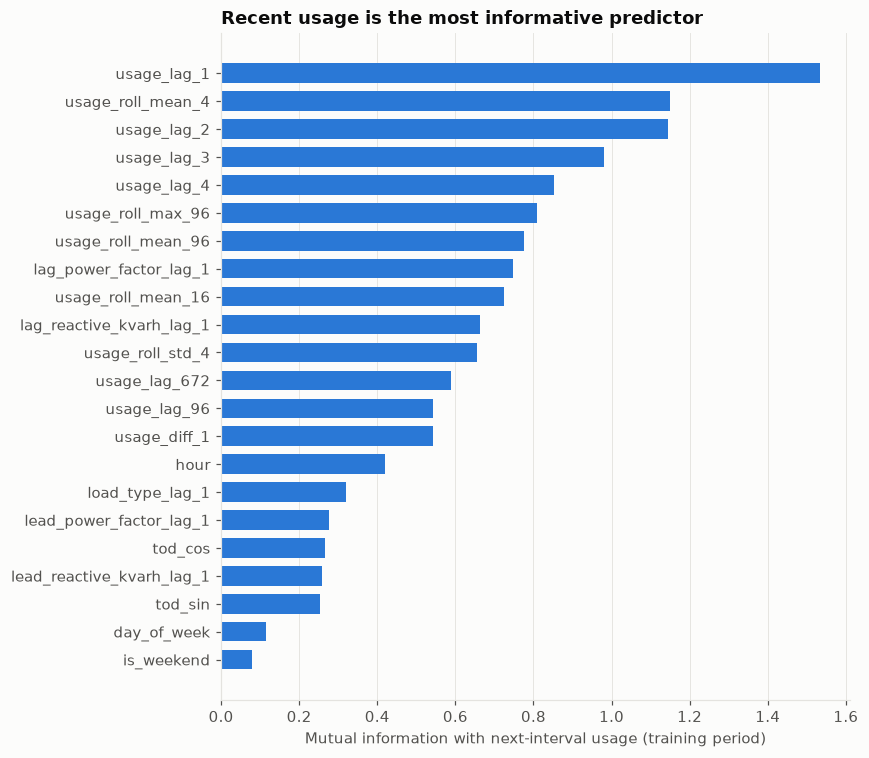

In [7]:
X_tr = train[predictor_cols]
y_tr = train.target_usage_kwh
pearson = X_tr.corrwith(y_tr)
discrete = [c in ('hour', 'day_of_week', 'is_weekend', 'load_type_lag_1') for c in predictor_cols]
mi = mutual_info_regression(X_tr, y_tr, discrete_features=discrete, random_state=0)
screen = (pd.DataFrame({'pearson_r': pearson, 'abs_pearson_r': pearson.abs(), 'mutual_information': mi})
          .sort_values('mutual_information', ascending=False))
screen.to_csv(OUT / 'feature_screening_train.csv', index_label='feature')
print(screen.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 7))
order = screen.index[::-1]
ax.barh(order, screen.loc[order, 'mutual_information'], color=SERIES[0], height=0.7)
ax.set_xlabel('Mutual information with next-interval usage (training period)')
ax.set_title('Recent usage is the most informative predictor')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIG / 'fe_feature_screening.png', dpi=150)
plt.show()

## 8 Select feature groups by validation error
Feature groups are added one at a time:

calendar → recent usage → seasonal lags → rolling statistics → electrical lags → lagged load type.

Each set is scored with a fast probe model (histogram gradient boosting with fixed settings) fitted on training data and measured on validation data. **Rule:** calendar and recent usage are always kept, because they are the core inputs named in the proposal. Every later group is kept only if it lowers the probe's validation RMSE by at least 1% relative to the current set. Linear Regression scores are shown for reference.

Using the validation period here means the final validation scores are slightly optimistic. The untouched test period remains the unbiased check.

In [8]:
GROUPS = {
    'calendar': ['tod_sin', 'tod_cos', 'hour', 'day_of_week', 'is_weekend'],
    'recent_usage': ['usage_lag_1', 'usage_lag_2', 'usage_lag_3', 'usage_lag_4', 'usage_diff_1'],
    'seasonal_lags': ['usage_lag_96', 'usage_lag_672'],
    'rolling_stats': ['usage_roll_mean_4', 'usage_roll_std_4', 'usage_roll_mean_16',
                      'usage_roll_mean_96', 'usage_roll_max_96'],
    'electrical_lags': list(electrical_source),
    'load_type_lag': ['load_type_lag_1'],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(predictor_cols)
CORE = ['calendar', 'recent_usage']
MIN_GAIN = 0.01

def probe_scores(cols):
    probe = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, early_stopping=False, random_state=0)
    probe.fit(train[cols], train.target_usage_kwh)
    linear = LinearRegression().fit(train[cols], train.target_usage_kwh)
    return (metrics(val.target_usage_kwh, probe.predict(val[cols])),
            metrics(val.target_usage_kwh, linear.predict(val[cols])))

kept, log, best_rmse = [], [], None
for group, cols in GROUPS.items():
    trial = kept + cols
    probe_m, linear_m = probe_scores(trial)
    gain = None if best_rmse is None else (best_rmse - probe_m['RMSE']) / best_rmse
    keep = group in CORE or gain >= MIN_GAIN
    if keep:
        kept, best_rmse = trial, probe_m['RMSE']
    log.append({'step': f'+ {group}', 'n_features': len(trial), 'probe_val_MAE': probe_m['MAE'],
                'probe_val_RMSE': probe_m['RMSE'], 'probe_val_R2': probe_m['R2'],
                'linear_val_RMSE': linear_m['RMSE'], 'rmse_gain_vs_kept': gain, 'kept': keep})
ablation = pd.DataFrame(log)
ablation.to_csv(OUT / 'feature_group_ablation.csv', index=False)
SELECTED = kept
print(ablation.round(4).to_string(index=False))
print('\nSelected features (%d):' % len(SELECTED), SELECTED)

             step  n_features  probe_val_MAE  probe_val_RMSE  probe_val_R2  linear_val_RMSE  rmse_gain_vs_kept  kept
       + calendar           5        11.8445         19.5588        0.5961          24.8086                NaN  True
   + recent_usage          10         4.0671          8.8056        0.9181          12.2182             0.5498  True
  + seasonal_lags          12         4.1642          8.9202        0.9160          11.8483            -0.0130 False
  + rolling_stats          15         4.1017          8.8331        0.9176          12.1498            -0.0031 False
+ electrical_lags          14         3.9591          8.6641        0.9207          11.9937             0.0161  True
  + load_type_lag          15         3.9443          8.5991        0.9219          11.9995             0.0075 False

Selected features (14): ['tod_sin', 'tod_cos', 'hour', 'day_of_week', 'is_weekend', 'usage_lag_1', 'usage_lag_2', 'usage_lag_3', 'usage_lag_4', 'usage_diff_1', 'lag_reactive_kvarh_

## 9 Benchmarks versus the probe on the selected features
This is a sanity check only. The real model comparison happens in `03_model_development.ipynb`.

                              MAE    RMSE     R2
Persistence                 5.756  12.701  0.830
Daily seasonal             15.283  28.906  0.118
Weekly seasonal            13.032  25.065  0.337
Probe (selected features)   3.959   8.664  0.921


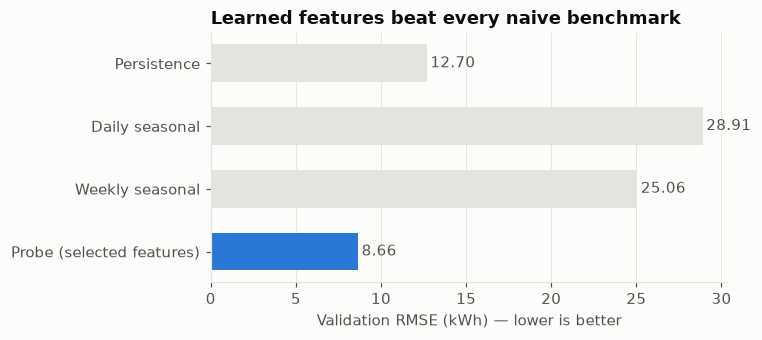

In [9]:
probe_m, _ = probe_scores(SELECTED)
compare = pd.concat([bench[bench.split == 'validation'].drop(columns='split').set_index('benchmark'),
                     pd.DataFrame([probe_m], index=['Probe (selected features)'])])
print(compare.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
colors = [GRID if 'Probe' not in n else SERIES[0] for n in compare.index]
ax.barh(compare.index[::-1], compare.RMSE[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(compare.RMSE[::-1]):
    ax.text(v + 0.2, y, f'{v:.2f}', va='center', color=INK_2)
ax.set_xlabel('Validation RMSE (kWh) — lower is better')
ax.set_title('Learned features beat every naive benchmark')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIG / 'fe_benchmarks_vs_probe.png', dpi=150)
plt.show()

## 10 Export the feature table and handover files
- `all_datasets/steel_features.csv`: one row per eligible target interval, with the `split` label, every candidate predictor, the benchmark forecasts and `analysis_load_type` for grouped error analysis.
- `outputs/features/feature_list.json`: the agreed predictors, the categorical columns and the documented exclusions.

Kennard should use only `split == 'train'` rows for exploratory decisions.

In [10]:
DEST = ROOT / 'all_datasets' / 'steel_features.csv'
eligible.to_csv(DEST, index=False, date_format='%Y-%m-%d %H:%M:%S')
reloaded = pd.read_csv(DEST, parse_dates=['date', 'origin'])
assert len(reloaded) == len(eligible) and reloaded[SELECTED].isna().sum().sum() == 0

feature_list = {
    'target': 'target_usage_kwh',
    'selected_features': SELECTED,
    'categorical_features': [c for c in ['day_of_week', 'hour'] if c in SELECTED],
    'all_candidate_groups': GROUPS,
    'benchmarks': BENCHMARKS,
    'selection_rule': f'Core groups {CORE} always kept; later groups kept if probe validation RMSE improves by >= {MIN_GAIN:.0%}.',
    'excluded': {
        'CO2(tCO2)': 'Near-copy of the target (r ~ 0.99); leakage.',
        'Same-interval electrical readings / Load_Type': 'Not measured at the forecast origin.',
        'Load_Type at target time': 'Not a fixed schedule in this data; kept only as analysis_load_type.',
        'month': 'Validation/test months are outside the training range; would require extrapolation.',
    },
    'feature_table': 'all_datasets/steel_features.csv',
    'feature_table_sha256_lf': text_sha256(DEST),
    'environment': {'python': platform.python_version(), 'pandas': pd.__version__,
                    'numpy': np.__version__, 'scikit-learn': sklearn.__version__},
}
(OUT / 'feature_list.json').write_text(json.dumps(feature_list, indent=2), encoding='utf-8')
print(json.dumps({k: feature_list[k] for k in ['selected_features', 'categorical_features']}, indent=2))
print('Exported', DEST.relative_to(ROOT), eligible.shape)

{
  "selected_features": [
    "tod_sin",
    "tod_cos",
    "hour",
    "day_of_week",
    "is_weekend",
    "usage_lag_1",
    "usage_lag_2",
    "usage_lag_3",
    "usage_lag_4",
    "usage_diff_1",
    "lag_reactive_kvarh_lag_1",
    "lead_reactive_kvarh_lag_1",
    "lag_power_factor_lag_1",
    "lead_power_factor_lag_1"
  ],
  "categorical_features": [
    "day_of_week",
    "hour"
  ]
}
Exported all_datasets/steel_features.csv (34368, 30)


## Completion checklist
- Target aligned once; all predictors use information available at the forecast origin (asserted in section 4).
- CO₂, same-interval electrical readings, target-time `Load_Type` and month were excluded, with reasons recorded.
- Chronological, whole-day 70/15/15 split shared in `split_boundaries.json`.
- Persistence, daily- and weekly-seasonal benchmarks computed on training and validation data.
- Feature groups selected by validation error under a fixed rule; test rows never scored.